In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Consistent plot style across all notebooks in this course

sns.set_theme(style='whitegrid', palette='muted') 
# adds a light grid background to all plots, making it easier to read values off the axes
# uses softer, less saturated colours which look more professional than matplotlib's default bright colours

plt.rcParams['figure.dpi'] = 110 
# increases the resolution of plots so they appear sharper, especially on high-resolution screens

print('Environment ready.')

Environment ready.


In [3]:
wine_white = pd.read_csv("datasets/winequality-white-train.csv")

## Basic Checks

In [4]:
wine_white.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.18,0.40,1.6,0.047,22.0,102.0,0.99370,3.28,0.44,10.7,5
1,6.9,0.24,0.36,20.8,0.031,40.0,139.0,0.99750,3.20,0.33,11.0,6
2,6.3,0.18,0.36,1.2,0.034,26.0,111.0,0.99074,3.16,0.51,11.0,6
3,6.2,0.21,0.38,6.8,0.036,64.0,245.0,0.99510,3.06,0.36,9.3,6
4,8.5,0.26,0.21,16.2,0.074,41.0,197.0,0.99800,3.02,0.50,9.8,3


In [5]:
# Shape
wine_white.shape

(3168, 12)

In [6]:
# Data types
wine_white.dtypes

fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

In [7]:
# Summary statistics
wine_white.describe().round(2)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,3168.00,3168.00,3168.00,3168.00,3168.00,3168.00,3168.00,3168.00,3168.00,3168.00,3168.00,3168.00
mean,6.84,0.28,0.33,5.85,0.05,34.75,136.99,0.99,3.19,0.49,10.59,5.86
std,0.87,0.10,0.12,4.71,0.02,16.62,42.81,0.00,0.15,0.11,1.22,0.89
min,3.80,0.08,0.00,0.60,0.01,2.00,9.00,0.99,2.72,0.22,8.00,3.00
25%,6.30,0.21,0.27,1.60,0.04,23.00,106.00,0.99,3.09,0.41,9.50,5.00
50%,6.80,0.26,0.32,4.70,0.04,33.00,133.00,0.99,3.18,0.48,10.40,6.00
75%,7.30,0.33,0.39,8.80,0.05,45.00,166.00,1.00,3.29,0.55,11.40,6.00
max,14.20,1.00,1.66,26.05,0.29,146.50,366.50,1.00,3.82,1.08,14.05,9.00


In [8]:
# Null values
wine_white.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

0 null values

## Binarising `quality`
We binarise quality with quality >= 7 being a good wine, and quality < 7 being a bad wine

In [9]:
wine_white['quality'] = (wine_white['quality'] >= 7).astype(int)

In [10]:
wine_white.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.18,0.40,1.6,0.047,22.0,102.0,0.99370,3.28,0.44,10.7,0
1,6.9,0.24,0.36,20.8,0.031,40.0,139.0,0.99750,3.20,0.33,11.0,0
2,6.3,0.18,0.36,1.2,0.034,26.0,111.0,0.99074,3.16,0.51,11.0,0
3,6.2,0.21,0.38,6.8,0.036,64.0,245.0,0.99510,3.06,0.36,9.3,0
4,8.5,0.26,0.21,16.2,0.074,41.0,197.0,0.99800,3.02,0.50,9.8,0


In [11]:
wine_white['quality'].value_counts()

quality
0    2508
1     660
Name: count, dtype: int64

In [17]:
print("Positive class rate:", wine_white['quality'].mean().round(2))

Positive class rate: 0.21


## Univariate Distributions

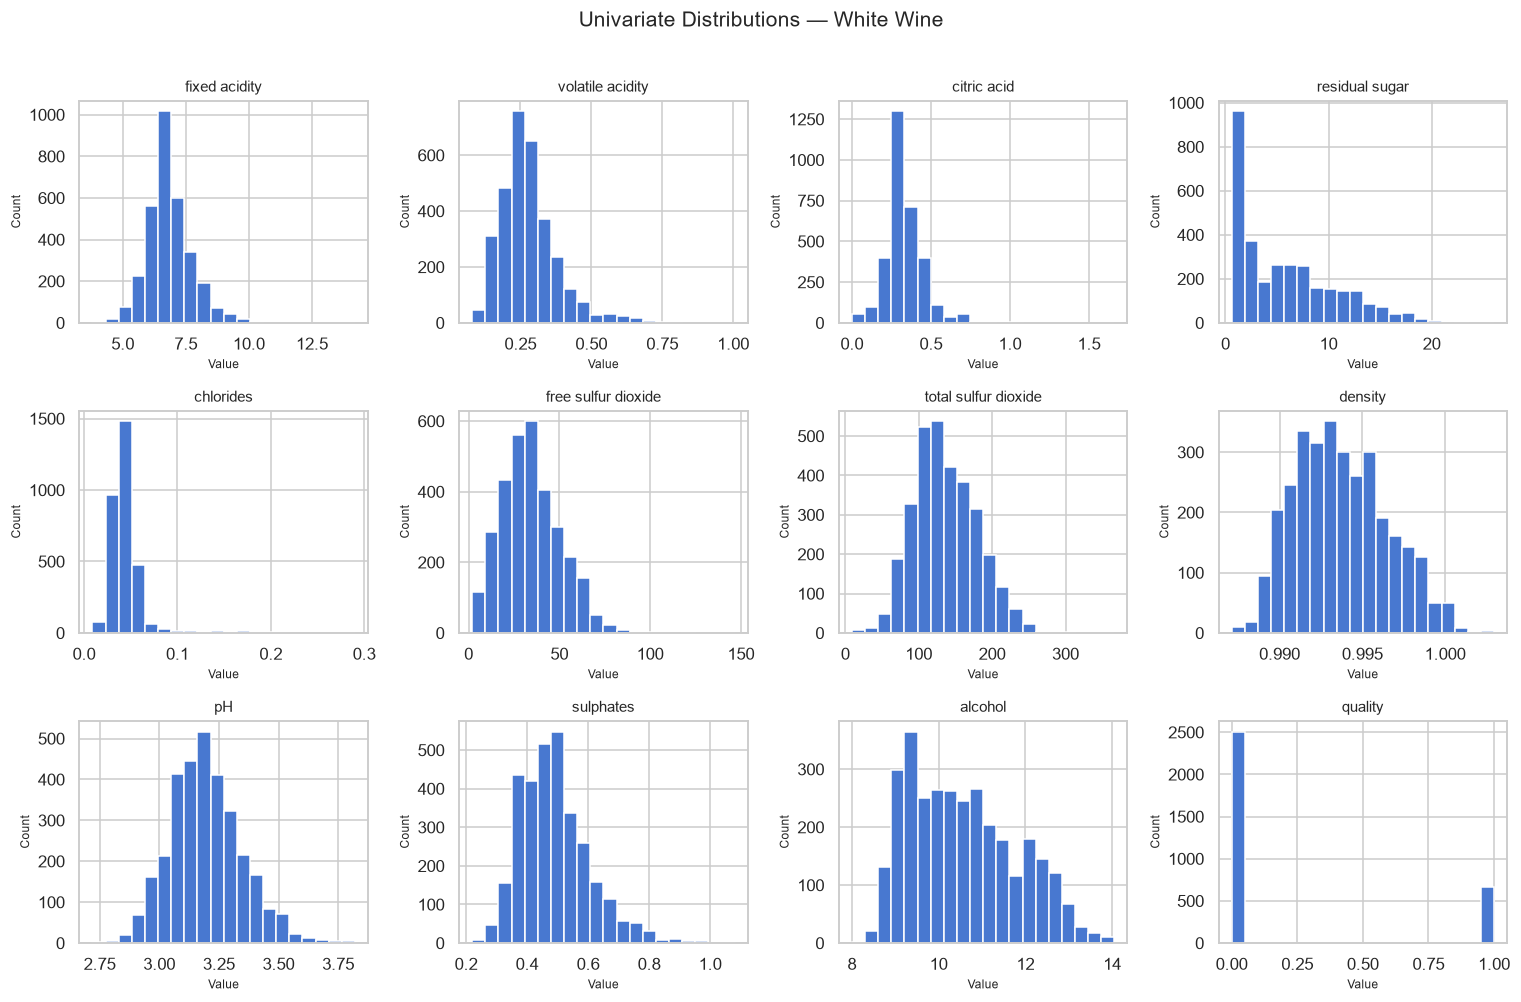

In [13]:
fig, axes = plt.subplots(3, 4, figsize=(14, 9))

# Flatten the 2D axes array (shape 3x4) into a 1D array of 12 elements
for ax, col in zip(axes.flatten(), wine_white.columns):
    ax.hist(wine_white[col], bins=20, edgecolor='white')
    ax.set_title(col, fontsize=10)
    ax.set_xlabel('Value', fontsize=8)
    ax.set_ylabel('Count', fontsize=8)

plt.suptitle('Univariate Distributions — White Wine', y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

#### Well behaved
`pH`: Unimodal and fully symmetric, forming a classic bell-shaped distribution.

`Density`: Nearly symmetric and bell-shaped, with a subtle shift toward higher values.

`Total Sulfur Dioxide`: Broad, well-behaved bell-shaped distribution.

`Fixed Acidity`: Mostly symmetric, trailing off slightly into higher values.

#### Skewed/Multimodal
`Volatile Acidity`: Right-skewed, concentrated heavily at low values with a long upper tail.

`Free Sulfur Dioxide`: Right-skewed, with most observations clustered in the lower region tapering toward higher values.

`Sulphates`: Moderately right-skewed, peaking early and trailing off gradually.

`Citric Acid`: Sharply peaked around a central concentration, with a thin upper tail.

`Residual Sugar`: Heavily right-skewed, with the vast majority concentrated at low levels and a long tail extending toward sweeter wines.

`Chlorides`: Tightly clustered near low values with a severe, sparse upper tail.

`Alcohol`: Bimodal with distinct secondary peaks

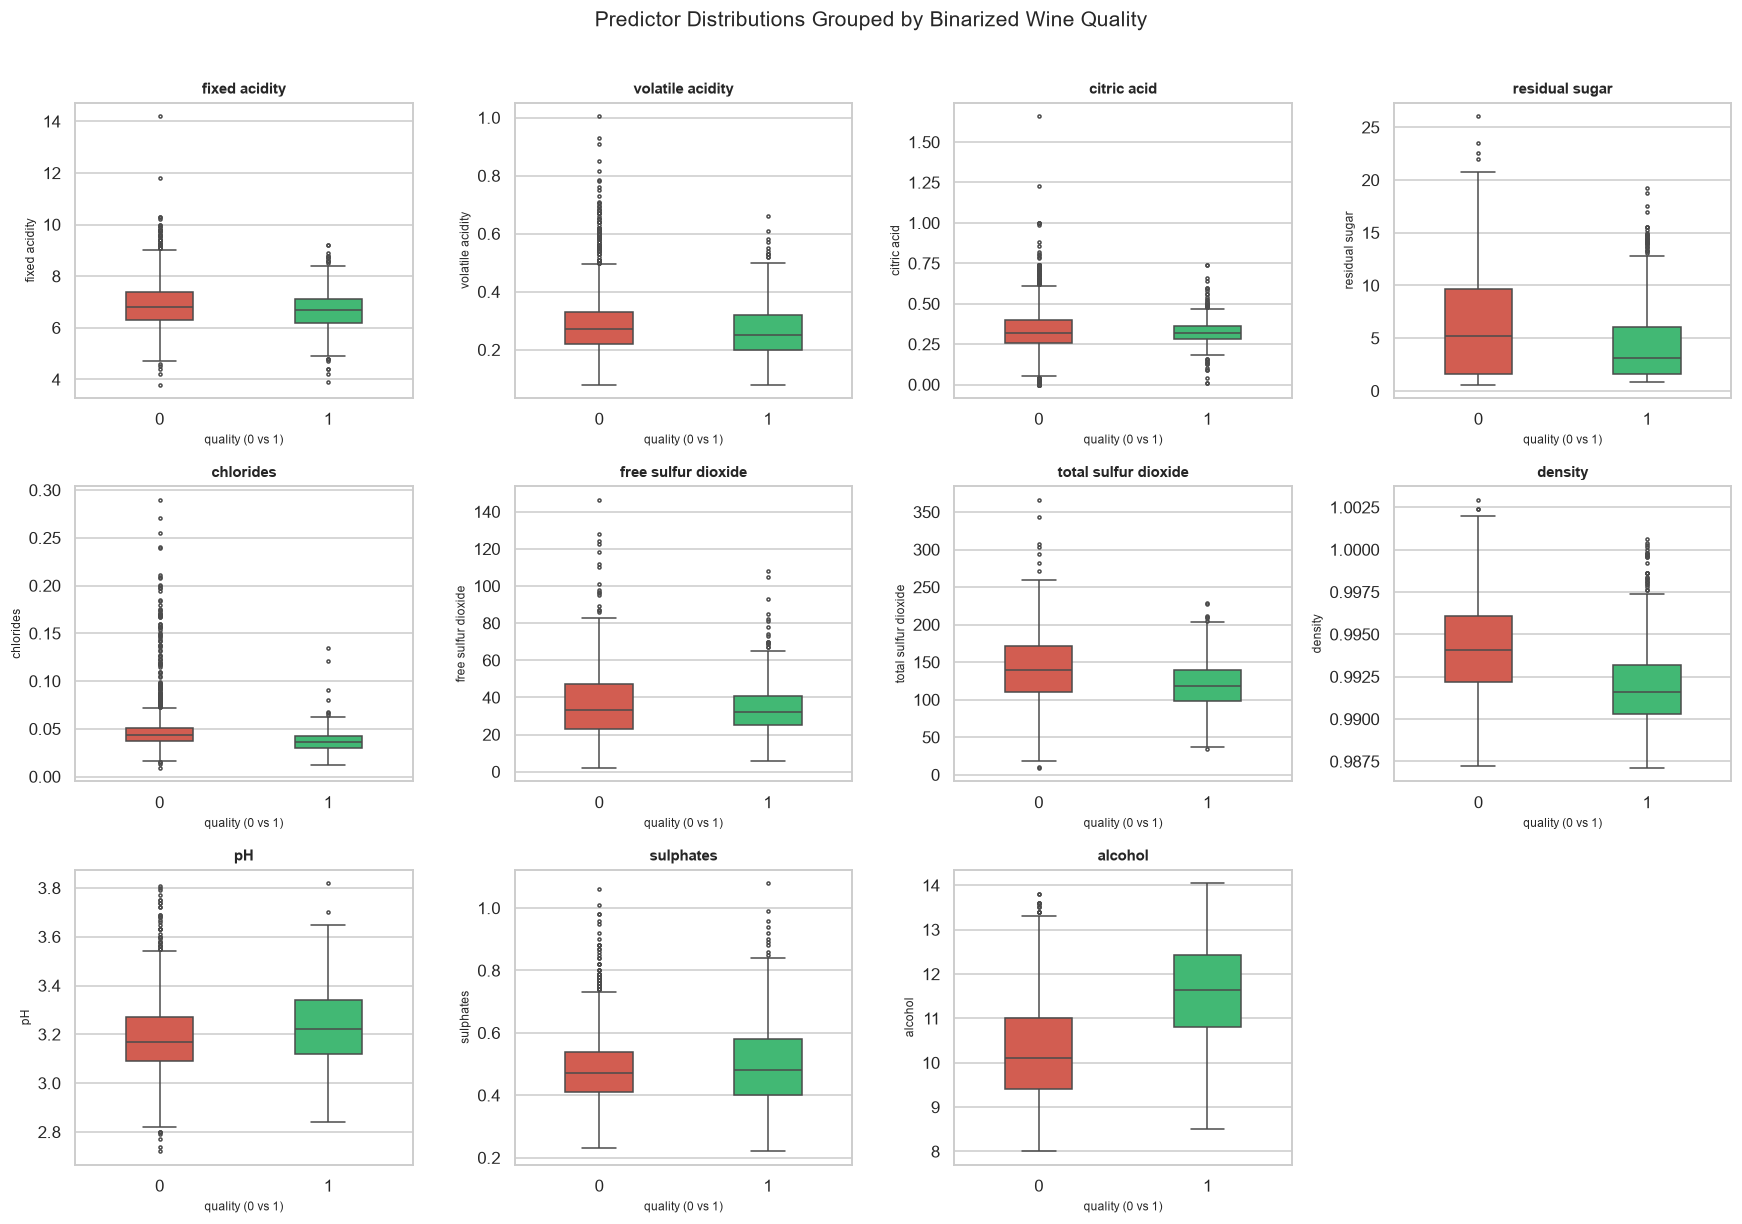

In [14]:
# Predictors excluding the binarized target 'quality'
predictors = [
    'fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
    'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
    'pH', 'sulphates', 'alcohol'
]

fig, axes = plt.subplots(3, 4, figsize=(16, 11))
axes_flat = axes.flatten()

for i, pred in enumerate(predictors):
    ax = axes_flat[i]
    sns.boxplot(
        data=wine_white, 
        x='quality', 
        y=pred, 
        hue='quality',    # Assign hue to match x
        legend=False,     # Suppress extra legend
        ax=ax, 
        palette=['#e74c3c', '#2ecc71'], 
        width=0.4,
        fliersize=2
    )
    ax.set_title(pred, fontsize=10, fontweight='bold')
    ax.set_xlabel('quality (0 vs 1)', fontsize=8)
    ax.set_ylabel(pred, fontsize=8)

# Remove the empty 12th panel in the 3x4 grid
fig.delaxes(axes_flat[-1])

plt.suptitle('Predictor Distributions Grouped by Binarized Wine Quality', y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

Some variables that may be significant based on visual inspection of the box plots:

- `alcohol`: Positive class shows a significantly higher median and overall distribution compared to negative class, with minimal overlap in their interquartile ranges. 
- `density`: Positive class has a noticeably lower median density than negative class, displaying clear visual separation between the two distributions. 
- `residual sugar`: Negative class has a higher median and a noticeably wider distribution extending into higher concentrations compared to positive class.   
- `total sulfur dioxide`: Positive class exhibits a lower median concentration compared to negative class.   

## Correlation Matrix

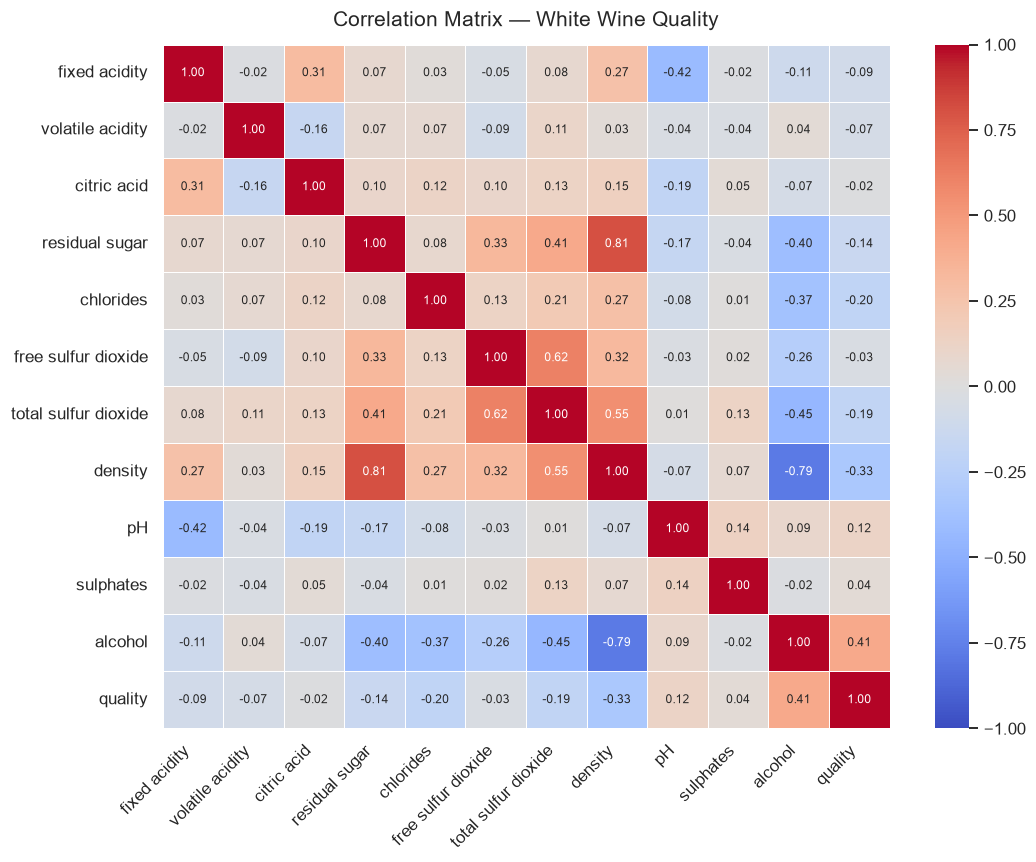

In [18]:
# Compute correlation matrix for the white wine dataset
corr = wine_white.corr()

# Increased figure size (10x8) so numbers and labels don't overlap with 12 features
fig, ax = plt.subplots(figsize=(10, 8))

# Draw the heatmap
sns.heatmap(
    corr, 
    annot=True, 
    fmt='.2f', 
    cmap='coolwarm',
    vmin=-1, 
    vmax=1, 
    linewidths=0.5, 
    annot_kws={"size": 8},  # Slightly smaller text size for clarity
    ax=ax
)

# Formatting title and axis tick labels
ax.set_title('Correlation Matrix — White Wine Quality', fontsize=14, pad=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

- `density` $\leftrightarrow$ `residual sugar` ($r = 0.81$): This is the strongest positive correlation between any two predictors in the dataset. 
- `density` $\leftrightarrow$ `alcohol` ($r = -0.79$): This is the strongest negative correlation between any two predictors in the dataset. Higher alcohol content lowers the density of the wine.
- `alcohol` $\leftrightarrow$ `quality` ($r = 0.41$): Has the strongest direct positive correlation with quality.
- `density` $\leftrightarrow$ `quality` ($r = -0.33$): Has the strongest negative correlation with quality. However, note that density is heavily tied to alcohol ($r = -0.79$), which has the highest positive correlation with `quality`